# Bước 1. Business Understanding and Analytic Approach: hiểu bài toán, đặt câu hỏi và chọn cách tiếp cận

Môn ADY201m, Bộ môn CF. Đề tài: *A One-Line Rule against Ten Models on a Popular Phishing Benchmark and What Near-Perfect Accuracy Really Measures*. Giảng viên hướng dẫn: Lê Võ Minh Thư. Nhóm 10: Nguyễn Đức Hùng - SE201567, Cao Huy - SE201674.

Đồ án gồm 6 bước, mỗi bước một notebook trong thư mục `Source Code`. Bảng dưới tóm tắt việc làm và sản phẩm của từng bước.

| STT | Notebook | Việc làm | Sản phẩm |
|---|---|---|---|
| 1 | `1. Business Understanding and Analytic Approach` | Hiểu bối cảnh, tìm khoảng trống, chốt 3 câu hỏi nghiên cứu | Bảng khoảng trống, 3 câu hỏi |
| 2 | `2. Data Collection, Understanding, Preparation` | Từ điển dữ liệu, kiểm tra ô trống, dòng trùng, miền giá trị, chia 50 cột số thành 3 nhóm theo thời điểm có được, chia tập huấn luyện, kiểm định, kiểm thử, tự kiểm rò rỉ | `Outputs/phishing_model_table.parquet`, từ điển dữ liệu, bảng số dòng trước và sau làm sạch |
| 3 | `3. Data Analysis with SQL` | Trả lời các câu hỏi mô tả bằng SQL (hai lớp, tên miền cấp cao, chỉ số tương đồng, ba câu hỏi nghiên cứu), đối chiếu với pandas | `Outputs/phishing.duckdb`, các bảng `sql_*.csv` |
| 4 | `4. Data Analysis with Python` | Khám phá phân bố, tương quan, ngoại lai, tên miền cấp cao, độ dài địa chỉ, trùng tên miền giữa các tập | Hình `b4_*`, bảng CSV |
| 5 | `5. Data Visualization` | Sơ đồ quy trình nhiều tầng, hình hai lớp, hình tên miền cấp cao, hình mười mô hình, hình giao thức câu hỏi 3 | Hình PDF, bảng LaTeX |
| 6 | `6. Modeling and Model Comparison` | Mốc đơn giản, mười mô hình học máy, thang bỏ dần đặc trưng, quy tắc một dòng, tên miền chưa thấy, kiểm định, thí nghiệm bổ sung | Bảng LaTeX, hình PDF |

**Bối cảnh kinh doanh.** Một chuyên viên an toàn thông tin ở ngân hàng hoặc nhà mạng phải chọn bộ lọc để chặn đường link giả trong tin nhắn và thư điện tử. Bộ lọc nào cũng bắt được phần lớn link lừa đảo thì chưa đủ.
Điều quyết định bộ lọc có sống được hay không là **tỷ lệ báo động giả**: nếu bộ lọc chặn nhầm quá nhiều đường link hợp lệ, người dùng sẽ tắt nó đi. Vì vậy người chọn bộ lọc cần biết hai con số: bộ lọc bắt được bao nhiêu link lừa đảo khi chỉ được chặn nhầm tối đa 1% link hợp lệ, và con số ấy có giữ nguyên khi gặp đường link khác với dữ liệu đã dùng để huấn luyện hay không.

**Một bộ dữ liệu mà mọi bài đều dùng.** PhiUSIIL (Prasad và Chandra, 2024) là bộ dữ liệu mở về địa chỉ lừa đảo được nhiều bài 2025 đến 2026 dùng, và các bài ấy thường báo độ chính xác trên 99% với mạng nơ-ron sâu và cách chia ngẫu nhiên.
Con số ấy làm người đọc tin rằng bài toán đã được giải. Đề tài này hỏi ngược lại: con số 99% thật ra đang đo điều gì, và bộ lọc có dùng được ngoài đời hay không.

**Ba lối tắt cần kiểm tra.** (1) Chỉ số tương đồng `URLSimilarityIndex` do chính tác giả dữ liệu dựng, nên có thể đã chứa gần như cả nhãn. (2) Dạng của địa chỉ, ví dụ có bắt đầu bằng `https://www.` hay không, có thể phản ánh cách thu thập dữ liệu chứ không phản ánh bản chất của lừa đảo. (3) Địa chỉ có đường dẫn phía sau tên miền hay chỉ là trang chủ.
Ba lối tắt này nằm ở mục 1.6, và chúng chính là lý do đề tài có một quy tắc một dòng làm mốc so sánh.

**Dữ liệu.** Một tệp CSV duy nhất của UCI Machine Learning Repository (giấy phép CC BY 4.0): 235.795 dòng, mỗi dòng một địa chỉ web, với các đặc trưng tính từ chính địa chỉ và từ trang web sau khi tải về. Số dòng vượt mức 30.000 dòng mà môn học ưu tiên (xem mục 1.1).
Đề tài **không thu thập địa chỉ mới**, và đây là giới hạn phải nói rõ trong bài.

**Điều phải nói thẳng:**
- Dữ liệu **không có cột thời gian**, nên không thể chia huấn luyện và kiểm tra theo thời gian như các bài dự báo. Thay vào đó đề tài dùng chia phân tầng, chia theo tên miền và chia theo tên miền cấp cao (TLD, đuôi như `.com`, `.org`).
- Trang UCI chỉ nói đặc trưng được trích từ mã nguồn trang và từ địa chỉ, không mô tả chi tiết cách thu thập hai lớp. Nếu hai lớp được thu thập theo hai cách khác nhau thì dạng địa chỉ có thể tách được chúng mà không liên quan gì tới việc lừa đảo.
- Trong tệp gốc, nhãn 1 là địa chỉ **hợp lệ** và nhãn 0 là lừa đảo. Cả bộ notebook đảo lại thành cột `phishing` (1 là lừa đảo) để lớp cần phát hiện là lớp dương.

## 1.1 Đọc tệp dữ liệu và ghi lại kích thước
Ô dưới tìm tệp CSV trong thư mục `Data`, đọc tệp và in số dòng, số cột, số ô trống, số địa chỉ trùng và số lượng từng lớp.
Cách đọc: mục Data của bài báo phải ghi đúng các kích thước này, kèm nguồn, năm và lý do dùng. Nhật ký làm sạch đầy đủ nằm ở Bước 2, ở đây chỉ bỏ địa chỉ trùng để các phép đếm của Bước 1 dùng cùng một bảng với các bước sau.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from style import *
setup()
plt.rcParams.update({"font.size": 8.5})
DATA = "../Data/"
NAME = "PhiUSIIL_Phishing_URL_Dataset.csv"
path = os.path.join(DATA, NAME)
if not os.path.exists(path):
    hits = glob.glob(DATA + "**/" + NAME, recursive=True)
    if not hits:
        raise FileNotFoundError("Không thấy " + NAME + " trong " + os.path.abspath(DATA))
    path = hits[0]
raw = pd.read_csv(path, encoding="utf-8-sig")
raw["phishing"] = 1 - raw["label"]                                   # trong tệp, nhãn 1 là hợp lệ; ở đây 1 là lừa đảo
df = raw.drop_duplicates("URL").copy()                               # bảng làm việc của Bước 1: chỉ bỏ địa chỉ trùng, làm sạch đầy đủ ở Bước 2
overview = pd.DataFrame([
    ("Tệp dữ liệu", NAME), ("Nguồn", "UCI Machine Learning Repository, bộ 967, CC BY 4.0"),
    ("Số dòng của tệp gốc", f"{len(raw):,}"), ("Số cột của tệp gốc", raw.shape[1] - 1),
    ("Số ô trống ở các cột số", int(raw.select_dtypes("number").isna().sum().sum())),
    ("Địa chỉ trùng (theo cột URL)", int(raw.URL.duplicated().sum())),
    ("Số dòng sau khi bỏ địa chỉ trùng", f"{len(df):,}"),
    ("Địa chỉ hợp lệ, lừa đảo (tệp gốc)", f"{int((raw.phishing == 0).sum()):,}, {int(raw.phishing.sum()):,}"),
    ("Địa chỉ hợp lệ, lừa đảo (sau khi bỏ trùng)", f"{int((df.phishing == 0).sum()):,}, {int(df.phishing.sum()):,}"),
    ("Số tên miền cấp cao (TLD) khác nhau", df.TLD.astype(str).str.lower().nunique()),
], columns=["muc", "gia_tri"])
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 70)
print(overview.to_string(index=False))
print("\nTệp gốc có cột thời gian không:", any("date" in c.lower() or "time" in c.lower() for c in raw.columns))

                                       muc                                            gia_tri
                               Tệp dữ liệu                  PhiUSIIL_Phishing_URL_Dataset.csv
                                     Nguồn UCI Machine Learning Repository, bộ 967, CC BY 4.0
                       Số dòng của tệp gốc                                            235,795
                        Số cột của tệp gốc                                                 56
                   Số ô trống ở các cột số                                                  0
              Địa chỉ trùng (theo cột URL)                                                425
          Số dòng sau khi bỏ địa chỉ trùng                                            235,370
         Địa chỉ hợp lệ, lừa đảo (tệp gốc)                                   134,850, 100,945
Địa chỉ hợp lệ, lừa đảo (sau khi bỏ trùng)                                   134,850, 100,520
       Số tên miền cấp cao (TLD) khác nhau                  

**Nhận xét:** tệp gốc có 235.795 dòng với 134.850 địa chỉ hợp lệ và 100.945 địa chỉ lừa đảo (42,8%). Không có ô trống ở các cột số. Có 425 địa chỉ trùng, cả 425 đều thuộc lớp lừa đảo, nên sau khi bỏ trùng còn 235.370 dòng (134.850 hợp lệ và 100.520 lừa đảo, tức 42,7%).
Tệp có 695 tên miền cấp cao khác nhau và không có cột thời gian. Số dòng gấp gần 8 lần mức 30.000 dòng mà môn học ưu tiên, nên kích thước dữ liệu đủ cho mười mô hình, năm seed và các cách chia khác nhau.
Hai lớp khá cân bằng (lớp lừa đảo chiếm khoảng 43%), nên lý do dùng PR-AUC và độ hiệu chuẩn ở các bước sau không phải là "lớp dương hiếm". Lý do đúng là bài toán được đánh giá ở ngưỡng báo động giả cố định 1%.

## 1.2 Bối cảnh: các bài đã báo độ chính xác bao nhiêu, và một quy tắc một dòng đạt bao nhiêu
Ô dưới đặt cạnh nhau bốn con số: độ chính xác của hai bài dùng PhiUSIIL, độ chính xác của quy tắc "địa chỉ không bắt đầu bằng `https://www.` thì là lừa đảo" trên chính dữ liệu này, và độ chính xác của cách đoán mọi địa chỉ là hợp lệ (mức sàn).
Quy tắc không ước lượng tham số nào nên không cần chia tập huấn luyện và kiểm thử. Ô tính quy tắc trên toàn bộ 235.370 địa chỉ đã bỏ trùng, ở Bước 6 sẽ tính lại riêng trên tập kiểm thử.
Cách đọc: mỗi chấm một cách làm, chấm càng sang phải thì độ chính xác càng cao. Chấm san hô là quy tắc một dòng của nhóm. Các bài khác dùng cách chia và tập kiểm thử khác nhau nên không so trực tiếp được, hình chỉ cho thấy hai mức độ lớn.
Hãy nhìn vị trí của chấm san hô: quy tắc một dòng thấp hơn bài tốt nhất chưa tới một điểm phần trăm, và cao hơn một bài dùng học sâu.

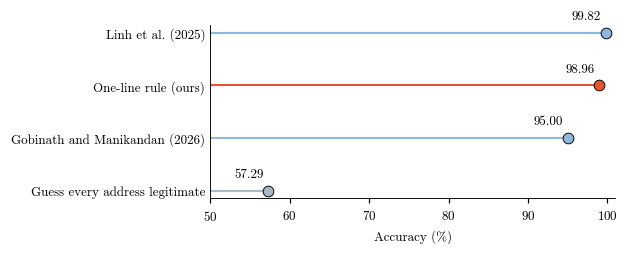

Mức sàn (đoán mọi địa chỉ là hợp lệ): 57.29% | quy tắc một dòng: 98.96%
Quy tắc bắt được 97.57% địa chỉ lừa đảo và báo động giả ở 0.00% địa chỉ hợp lệ


In [2]:
df["starts_https_www"] = df.URL.str.startswith("https://www.").astype(int)
y = df.phishing.to_numpy()
rule_flag = 1 - df.starts_https_www.to_numpy()                     # quy tắc một dòng: lừa đảo nếu địa chỉ không bắt đầu bằng https://www.
rule_accuracy = 100 * (rule_flag == y).mean()
floor_accuracy = 100 * (y == 0).mean()                              # đoán mọi địa chỉ là hợp lệ
reported = {"Guess every address legitimate": floor_accuracy, "Gobinath and Manikandan (2026)": 95.0, "One-line rule (ours)": rule_accuracy, "Linh et al. (2025)": 99.82}
order = sorted(reported, key=reported.get)
fig, ax = plt.subplots(figsize=(5.6, 2.2), layout="constrained")
for k, name in enumerate(order):
    color = OURS if "ours" in name else GREY if "Guess" in name else SKY
    ax.hlines(k, 50, reported[name], color=color, lw=1.4)
    ax.plot(reported[name], k, "o", color=color, ms=7, mec="black", mew=0.6, zorder=3)
    ax.text(reported[name] - 0.6, k + 0.2, f"{reported[name]:.2f}", ha="right", va="bottom", fontfamily=BOLD)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlim(50, 101)
ax.set_xlabel("Accuracy (%)")
ax.tick_params(axis="y", length=0)
save(fig, "b1_reported_accuracy")
print("Mức sàn (đoán mọi địa chỉ là hợp lệ): %.2f%% | quy tắc một dòng: %.2f%%" % (floor_accuracy, rule_accuracy))
print("Quy tắc bắt được %.2f%% địa chỉ lừa đảo và báo động giả ở %.2f%% địa chỉ hợp lệ" % (100 * rule_flag[y == 1].mean(), 100 * rule_flag[y == 0].mean()))

**Nhận xét:** quy tắc một dòng đạt 98,96% độ chính xác trên 235.370 địa chỉ, bắt 97,57% địa chỉ lừa đảo và không báo động giả nào. Mức sàn (đoán mọi địa chỉ là hợp lệ) là 57,29%.
Hai bài so sánh báo 95,00% (Gobinath và Manikandan, 2026) và 99,82% (Linh và cộng sự, 2025). Quy tắc một dòng cao hơn bài thứ nhất 3,96 điểm phần trăm và thấp hơn bài thứ hai 0,86 điểm phần trăm, trong khi chỉ cần một dòng lệnh và không huấn luyện gì.
Vì cách chia và tập kiểm thử khác nhau nên đây chưa phải kết luận, nhưng đủ để đặt câu hỏi: con số trên 99% có đo khả năng nhận ra lừa đảo hay chỉ đo cách dữ liệu được thu thập.

## 1.3 Tệp dữ liệu lớn cỡ nào và tên miền cấp cao phân bố ra sao
Ô dưới đếm số địa chỉ theo tên miền cấp cao (TLD) và vẽ 12 TLD đông nhất. Khung trái là số địa chỉ, khung phải là tỷ lệ địa chỉ lừa đảo của từng TLD.
Cách đọc: khung trái cho biết TLD nào chiếm phần lớn dữ liệu. Khung phải cho biết TLD nào gần như toàn lừa đảo hay toàn hợp lệ. Chênh lệch ở khung phải chính là lý do câu hỏi 3 thử mô hình trên TLD chưa thấy.
Đường đứt ở khung phải là tỷ lệ lừa đảo chung của cả tệp.

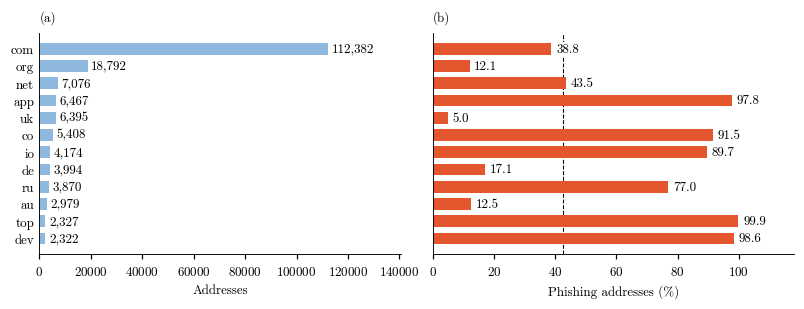

     addresses  phishing_pct
TLD                         
com     112382          38.8
org      18792          12.1
net       7076          43.5
app       6467          97.8
uk        6395           5.0
co        5408          91.5
io        4174          89.7
de        3994          17.1
ru        3870          77.0
au        2979          12.5
top       2327          99.9
dev       2322          98.6

Tỷ lệ lừa đảo chung: 42.7% | số TLD: 695 | ba TLD đông nhất giữ 58.7% số địa chỉ
Số TLD có từ 10 địa chỉ trở lên: 287 | số TLD chỉ có một địa chỉ: 154


In [3]:
df["TLD"] = df.TLD.astype(str).str.lower()
by_tld = df.groupby("TLD").agg(addresses=("phishing", "size"), phishing_pct=("phishing", lambda v: 100 * v.mean())).sort_values("addresses", ascending=False)
top = by_tld.head(12).iloc[::-1]
overall = 100 * df.phishing.mean()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), layout="constrained", sharey=True)
axes[0].barh(top.index, top.addresses, color=SKY, height=0.68)
for k, value in enumerate(top.addresses):
    axes[0].text(value + 0.012 * top.addresses.max(), k, f"{value:,}", va="center", fontfamily=BOLD)
axes[0].set_xlim(0, top.addresses.max() * 1.25)
axes[0].set_xlabel("Addresses")
axes[1].barh(top.index, top.phishing_pct, color=OURS, height=0.68)
for k, value in enumerate(top.phishing_pct):
    axes[1].text(value + 1.5, k, f"{value:.1f}", va="center", fontfamily=BOLD, bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
axes[1].axvline(overall, color="black", lw=0.7, ls="--", zorder=0)
axes[1].set_xlim(0, 118)
axes[1].set_xlabel("Phishing addresses (%)")
for ax in axes:
    ax.tick_params(axis="y", length=0)
panel(axes[0], "(a)")
panel(axes[1], "(b)")
save(fig, "b1_tld_size")
print(by_tld.head(12).round(1).to_string())
print("\nTỷ lệ lừa đảo chung: %.1f%% | số TLD: %d | ba TLD đông nhất giữ %.1f%% số địa chỉ" % (overall, len(by_tld), 100 * by_tld.addresses.head(3).sum() / len(df)))
print("Số TLD có từ 10 địa chỉ trở lên: %d | số TLD chỉ có một địa chỉ: %d" % ((by_tld.addresses >= 10).sum(), (by_tld.addresses == 1).sum()))

**Nhận xét:** ba TLD đông nhất là `.com` (112.382 địa chỉ), `.org` (18.792) và `.net` (7.076), cộng lại giữ 58,7% số địa chỉ. Tỷ lệ lừa đảo của ba TLD này rất khác nhau: 38,8% ở `.com`, 12,1% ở `.org` và 43,5% ở `.net`, so với 42,7% của cả tệp.
Phần còn lại là một đuôi dài: tệp có 695 TLD, nhưng chỉ 287 TLD có từ 10 địa chỉ trở lên và 154 TLD chỉ có đúng một địa chỉ. Nhiều TLD gần như chỉ có một lớp: `.top` (99,9%), `.dev` (98,6%) và `.app` (97,8%) gần như toàn lừa đảo, còn `.uk` (5,0%), `.org` (12,1%) và `.au` (12,5%) có rất ít.
Vì vậy một mô hình chỉ huấn luyện trên ba TLD phổ biến sẽ gặp 692 TLD còn lại (41,3% số địa chỉ) lần đầu tiên, trong khi tên TLD lại mang nhiều thông tin về nhãn. Đây là cơ sở của phép thử TLD chưa thấy ở Bước 6; các số chính xác sẽ được tính lại bằng SQL ở Bước 3.

## 1.4 Khoảng trống nghiên cứu
Bảng dưới tóm tắt bảy công trình. Cột "Đã làm gì" lấy từ tóm tắt đã kiểm chứng thông tin xuất bản (tác giả, tạp chí, năm, DOI), trừ dòng 2 (Rawla) và DOI của dòng 5 (Kapoor và Narayanan) chưa dò lại được từ nguồn gốc. Cột "Còn thiếu gì" là nhận định của nhóm sau khi đọc tóm tắt, nên cần đọc lại toàn văn của từng bài trước khi nộp. Bản nháp danh sách tài liệu nằm ở `Paper/references.bib`; các dòng TODO trong tệp là chỗ nhóm phải dò lại trước khi nộp.

| STT | Công trình | Đã làm gì | Còn thiếu gì so với bài toán của nhóm |
|---|---|---|---|
| 1 | Prasad và Chandra (2024), Computers & Security, DOI 10.1016/j.cose.2023.103545 | Công bố bộ PhiUSIIL (235.795 địa chỉ, 54 đặc trưng, UCI 2024) và khung phát hiện dựa trên chỉ số tương đồng địa chỉ và học tăng dần | Chưa thấy báo cáo điểm số còn lại khi bỏ chỉ số tương đồng |
| 2 | Rawla và cộng sự (2025), Procedia Computer Science, DOI 10.1016/j.procs.2025.04.003 | Mạng nơ-ron sâu trên PhiUSIIL, báo 99,38% với chia ngẫu nhiên 80/20 (con số theo đề cương, cần dò lại toàn văn) | Chưa thấy mốc đơn giản, chưa thử tên miền cấp cao chưa thấy |
| 3 | Linh và cộng sự (2025), Bulletin of Electrical Engineering and Informatics 14(6), DOI 10.11591/eei.v14i6.10099 | So nhiều mô hình học sâu trên PhiUSIIL, BiGRU tốt nhất với 99,82% ở chia 60:40, đưa vào tiện ích Chrome kết hợp khớp mờ | Chưa thấy so với một quy tắc đơn giản, chưa thấy phép thử trên tên miền chưa thấy |
| 4 | Gobinath và Manikandan (2026), Scientific Reports 16, 15794, DOI 10.1038/s41598-026-46481-2 | Khung học sâu ADUIN, báo 95% độ chính xác, 3,5% báo động giả, chia 70/15/15 | Chưa thấy so với mốc đơn giản, chưa thấy bàn về lối tắt trong đặc trưng |
| 5 | Kapoor và Narayanan (2023), Patterns 4(9), 100804, DOI 10.1016/j.patter.2023.100804 | Phân loại các kiểu rò rỉ dữ liệu và cho thấy rò rỉ làm kết quả học máy không lặp lại được | Là nghiên cứu chung, không có số liệu cho phát hiện lừa đảo |
| 6 | Van Calster và cộng sự (2019), BMC Medicine 17, 230, DOI 10.1186/s12916-019-1466-7 | Chỉ ra rằng một con số tổng hợp chưa đủ để tin mô hình dự đoán, cần xem cả độ hiệu chỉnh xác suất | Là bài về y học, không bàn về phát hiện lừa đảo |
| 7 | Kho mã nguồn mở `ollivianguy/phishing-url-detection` trên GitHub (không qua bình duyệt, truy cập 10/2026) | Kiểm tra rò rỉ trên PhiUSIIL: chỉ ra chỉ số tương đồng đúng 100 ở mọi địa chỉ hợp lệ, quy tắc một dòng dựa trên chỉ số ấy đúng 99,67%, mọi địa chỉ hợp lệ bắt đầu bằng `https://www.`; đánh giá ở mức báo động giả cố định 0,1% và thử tấn công đổi địa chỉ | Chỉ dùng random forest, không so nhiều họ mô hình; không có thang bỏ dần nhóm đặc trưng theo thời điểm có được; không chia theo tên miền; không thử trên TLD chưa thấy; không bàn về lối tắt "chỉ là trang chủ" |

**Khoảng trống (trong phạm vi các công trình đã đọc):** các bài đã bình duyệt trên PhiUSIIL (dòng 2 tới 4) báo độ chính xác từ 95% tới 99,82% bằng học sâu, và không bài nào hỏi vì sao bài toán dễ đến vậy. Một kho mã nguồn mở (dòng 7) đã chỉ ra rằng chỉ số tương đồng và tiền tố `https://www.` gần như chứa sẵn nhãn, và đã đánh giá ở mức báo động giả cố định, nhưng chỉ với một mô hình và một cách chia ngẫu nhiên.
Chưa thấy công trình nào làm cùng lúc những việc sau trên PhiUSIIL: so mười mô hình thuộc bốn họ với một quy tắc viết tay, bỏ dần các nhóm đặc trưng theo thời điểm có được, chấm lại bằng bộ đặc trưng không thấy tiền tố và chỉ trên các địa chỉ là trang chủ, chia theo tên miền, và thử trên TLD không có trong tập huấn luyện. Khi viết bài, dùng cách nói "among the studies we reviewed", không viết "no prior work", và trích dẫn kho mã nguồn ở dòng 7.

## 1.5 Ba câu hỏi nghiên cứu
Bảng thứ nhất nêu ba câu hỏi. Bảng thứ hai nối từng câu hỏi với bước, hình và bảng dự kiến trả lời câu hỏi ấy, để nhóm biết phải mở tệp nào khi bị hỏi "số này ở đâu ra". Tên truy vấn, hình và bảng cụ thể sẽ được điền khi hoàn thành Bước 3 tới Bước 6.

| STT | Câu hỏi nghiên cứu |
|---|---|
| 1 | Hai lớp địa chỉ (lừa đảo và hợp lệ) khác nhau thế nào về dạng địa chỉ, tên miền cấp cao và chỉ số tương đồng? |
| 2 | Trong mười mô hình thuộc bốn họ, mô hình nào phân biệt lừa đảo với hợp lệ tốt nhất khi chia phân tầng, và các mô hình có tách được nhau không? |
| 3 | Con số gần tuyệt đối còn lại bao nhiêu khi bỏ chỉ số tương đồng, khi chỉ giữ đặc trưng biết trước lúc mở trang, khi bộ lọc không được thấy tiền tố `https://www.`, khi thay mô hình bằng một quy tắc một dòng, và khi gặp tên miền hoặc TLD chưa từng thấy lúc huấn luyện? |

**Bảng ánh xạ từng câu hỏi tới truy vấn, hình và bảng trả lời:**

| STT | Câu hỏi | Truy vấn SQL (Bước 3) | Phân tích Python (Bước 4, Bước 6) | Hình trả lời | Bảng trả lời |
|---|---|---|---|---|---|
| 1 | Hai lớp khác nhau thế nào | So hai lớp, xếp hạng TLD, chỉ số tương đồng theo khoảng 10 điểm | Mục tương quan với nhãn, phân bố, ngoại lai (Bước 4) | Hình tỷ lệ địa chỉ bắt đầu bằng `https://www.`, hình TLD | Bảng mô tả bộ dữ liệu, bảng so hai lớp |
| 2 | Mô hình nào tốt nhất, có tách được nhau không | Bảng đặc trưng bàn giao cho Bước 6 | Bước 6 (mười mô hình, 5 seed), kiểm định cặp | Hình so sánh mười mô hình | Bảng sai số và thời gian huấn luyện, bảng kiểm định |
| 3 | Con số gần tuyệt đối còn lại bao nhiêu | Câu hỏi về nhóm đặc trưng và về TLD | Bước 6 (thang bảy bộ đặc trưng gồm bộ không thấy tiền tố, chấm riêng trên địa chỉ là trang chủ, quy tắc một dòng, chia theo tên miền, TLD chưa thấy, chi phí bộ lọc) | Hình quy tắc một dòng so với mô hình, hình TLD chưa thấy | Bảng thang đặc trưng, bảng TLD chưa thấy, bảng chi phí |

Ba câu hỏi chỉ được nêu một lần ở Introduction và trả lời ngắn ở Conclusion của bài báo. Thân bài đi theo phương pháp giải bài toán: chuẩn bị dữ liệu, phân tích mô tả, thiết lập thí nghiệm, mô hình, đánh giá và kiểm định.

**Quy tắc trung thực:** báo cáo cả quy tắc một dòng lẫn mười mô hình, không chỉ bộ đặc trưng cho điểm cao nhất. Chỉ viết "tốt hơn" khi kiểm định cho phép. Nếu mười mô hình hòa nhau ở mức trần thì đó chính là kết quả, không phải lỗi.

## 1.6 Ba lối tắt trong dữ liệu
Phần này đo ba lối tắt đã nêu ở phần bối cảnh. Hai ô đầu đo chỉ số tương đồng `URLSimilarityIndex` và tiền tố `https://www.`; ba ô cuối đo lối tắt thứ ba, địa chỉ có đường dẫn hay chỉ là trang chủ. Với từng lớp, ô dưới in tỷ lệ địa chỉ bắt đầu bằng `https://www.`, tỷ lệ địa chỉ có chỉ số tương đồng đúng bằng 100 và giá trị trung bình của chỉ số. Ô cũng thử quy tắc "chỉ số tương đồng dưới 100 thì là lừa đảo" để xem chỉ riêng chỉ số ấy tách hai lớp tới đâu.

**Cách đọc:** nếu một lớp có gần như toàn bộ giá trị ở một mức còn lớp kia gần như không có, thì cột ấy gần như đã chứa sẵn nhãn. Quy tắc nào có số báo động giả bằng 0 thì chưa cần mô hình học máy để đạt mức đó.

**Lưu ý:** trang UCI không mô tả công thức tính chỉ số tương đồng, nên nhóm chưa biết chính xác nó được dựng thế nào. Việc nó gần như chứa sẵn nhãn là điều nhóm cần đo, không phải điều đã biết trước.

In [4]:
sim = df.URLSimilarityIndex
per_class = pd.DataFrame({
    "dia_chi": df.groupby("phishing").size(),
    "bat_dau_https_www_pct": 100 * df.groupby("phishing").starts_https_www.mean(),
    "chi_so_dung_100_pct": 100 * (sim == 100).groupby(df.phishing).mean(),
    "chi_so_trung_binh": sim.groupby(df.phishing).mean(),
}).rename(index={0: "legitimate", 1: "phishing"})
print(per_class.round(2).to_string())
shortcut = (sim < 100).astype(int).to_numpy()                       # quy tắc: chỉ số tương đồng dưới 100 thì là lừa đảo
print("\nQuy tắc 'chỉ số tương đồng dưới 100': độ chính xác %.2f%% | bắt %.2f%% địa chỉ lừa đảo | báo động giả %.2f%%" % (100 * (shortcut == y).mean(), 100 * shortcut[y == 1].mean(), 100 * shortcut[y == 0].mean()))
print("Quy tắc 'không bắt đầu bằng https://www.': độ chính xác %.2f%% | bắt %.2f%% địa chỉ lừa đảo | báo động giả %.2f%%" % (rule_accuracy, 100 * rule_flag[y == 1].mean(), 100 * rule_flag[y == 0].mean()))
print("Địa chỉ lừa đảo có chỉ số tương đồng đúng 100: %d trên %d" % (((sim == 100) & (df.phishing == 1)).sum(), int(df.phishing.sum())))
print("Địa chỉ lừa đảo bắt đầu bằng https://www.: %d trên %d" % (int(((df.starts_https_www == 1) & (df.phishing == 1)).sum()), int(df.phishing.sum())))
print("Báo động giả tuyệt đối (số địa chỉ hợp lệ bị gán là lừa đảo): chỉ số dưới 100 = %d, không bắt đầu bằng https://www. = %d" % (((sim < 100) & (df.phishing == 0)).sum(), ((df.starts_https_www == 0) & (df.phishing == 0)).sum()))

            dia_chi  bat_dau_https_www_pct  chi_so_dung_100_pct  chi_so_trung_binh
phishing                                                                          
legitimate   134850                 100.00               100.00             100.00
phishing     100520                   2.43                 0.78              49.65

Quy tắc 'chỉ số tương đồng dưới 100': độ chính xác 99.67% | bắt 99.22% địa chỉ lừa đảo | báo động giả 0.00%
Quy tắc 'không bắt đầu bằng https://www.': độ chính xác 98.96% | bắt 97.57% địa chỉ lừa đảo | báo động giả 0.00%
Địa chỉ lừa đảo có chỉ số tương đồng đúng 100: 786 trên 100520
Địa chỉ lừa đảo bắt đầu bằng https://www.: 2445 trên 100520
Báo động giả tuyệt đối (số địa chỉ hợp lệ bị gán là lừa đảo): chỉ số dưới 100 = 0, không bắt đầu bằng https://www. = 0


**Nhận xét:** mọi địa chỉ hợp lệ (134.850 trên 134.850) đều bắt đầu bằng `https://www.` và có chỉ số tương đồng đúng 100 (ô trên đếm được 0 địa chỉ hợp lệ bị cả hai quy tắc gán nhầm), trong khi chỉ 2,43% địa chỉ lừa đảo bắt đầu như vậy. Chỉ số tương đồng trung bình là 100,00 ở lớp hợp lệ và 49,65 ở lớp lừa đảo. Quy tắc "chỉ số tương đồng dưới 100 thì là lừa đảo" đạt 99,67% độ chính xác, bắt 99,22% địa chỉ lừa đảo và không báo động giả nào (99.734 địa chỉ lừa đảo có chỉ số dưới 100, chỉ 786 địa chỉ còn lại có chỉ số 100). Quy tắc "không bắt đầu bằng `https://www.` thì là lừa đảo" đạt 98,96%, bắt 97,57% và cũng không báo động giả nào. Hai lối tắt đều gần như đã chứa nhãn. Câu hỏi 3 vì thế không hỏi mô hình có đạt 99% hay không, mà hỏi điểm số còn lại bao nhiêu khi lấy từng lối tắt đi.

### Lối tắt thứ ba: địa chỉ có đường dẫn hay chỉ là trang chủ
Ô dưới tách phần đứng sau tên miền của mỗi địa chỉ (ví dụ `/login/index.html`) và đếm, ở từng lớp, bao nhiêu địa chỉ có phần ấy. Ô cũng thử quy tắc "có đường dẫn thì là lừa đảo", gộp quy tắc này với quy tắc `https://www.`, và đếm tiền tố chữ của cột tên file `FILENAME` theo từng lớp.
Cách đọc: nếu lớp hợp lệ không có địa chỉ nào có đường dẫn thì mọi địa chỉ hợp lệ đều là trang chủ. Khi đó độ dài địa chỉ và số ký tự đặc biệt cũng gián tiếp chứa nhãn. Cột `FILENAME` không đưa vào mô hình, nhưng nếu tiền tố của nó khác nhau giữa hai lớp thì hai lớp nhiều khả năng được gom từ những nguồn khác nhau.

In [5]:
rest = df.URL.str.replace(r"^[a-zA-Z]+://[^/]+", "", regex=True)          # phần còn lại sau tên miền, ví dụ "/login/index.html"
df["has_path"] = (rest.str.len() > 0).astype(int)                          # 1 nếu địa chỉ có thêm gì đó sau tên miền
source = df.FILENAME.str.extract(r"^([a-z]*)")[0].replace("", "chỉ có số")  # tiền tố chữ của tên file
path_table = pd.DataFrame({
    "dia_chi": df.groupby("phishing").size(),
    "co_duong_dan_pct": 100 * df.groupby("phishing").has_path.mean(),
    "chi_la_trang_chu_pct": 100 * (1 - df.groupby("phishing").has_path.mean()),
}).rename(index={0: "legitimate", 1: "phishing"})
print(path_table.round(2).to_string())
path_flag = df.has_path.to_numpy()                                         # quy tắc: có đường dẫn thì là lừa đảo
print("\nQuy tắc 'có đường dẫn sau tên miền': độ chính xác %.2f%% | bắt %.2f%% địa chỉ lừa đảo | báo động giả %.2f%%" % (100 * (path_flag == y).mean(), 100 * path_flag[y == 1].mean(), 100 * path_flag[y == 0].mean()))
both = ((df.starts_https_www == 0) | (df.has_path == 1)).astype(int).to_numpy()
print("Gộp hai quy tắc (không bắt đầu bằng https://www. HOẶC có đường dẫn): độ chính xác %.2f%% | bắt %.2f%% | báo động giả %.2f%%" % (100 * (both == y).mean(), 100 * both[y == 1].mean(), 100 * both[y == 0].mean()))
print("\nTiền tố chữ của tên file theo lớp:")
print(pd.crosstab(source, df.phishing.map({0: "legitimate", 1: "phishing"})).to_string())

            dia_chi  co_duong_dan_pct  chi_la_trang_chu_pct
phishing                                                   
legitimate   134850               0.0                 100.0
phishing     100520              59.7                  40.3

Quy tắc 'có đường dẫn sau tên miền': độ chính xác 82.79% | bắt 59.70% địa chỉ lừa đảo | báo động giả 0.00%
Gộp hai quy tắc (không bắt đầu bằng https://www. HOẶC có đường dẫn): độ chính xác 99.73% | bắt 99.38% | báo động giả 0.00%

Tiền tố chữ của tên file theo lớp:
phishing   legitimate  phishing
0                              
chỉ có số      134850     55021
m                   0       380
mw                  0     36283
op                  0       548
oph                 0      8288


**Nhận xét:** không có địa chỉ hợp lệ nào có đường dẫn sau tên miền (0 trên 134.850), tức mọi địa chỉ hợp lệ đều là trang chủ, trong khi 59,7% địa chỉ lừa đảo có đường dẫn. Riêng quy tắc "có đường dẫn thì là lừa đảo" chỉ đạt 82,79% độ chính xác, nhưng vẫn không báo động giả nào. Gộp nó với quy tắc `https://www.` cho 99,73% độ chính xác, bắt 99,38% địa chỉ lừa đảo và vẫn không báo động giả nào. Hai điều kiện viết tay này đã cao hơn cả quy tắc dựa trên chỉ số tương đồng (99,67%).
Cột tên file cho thấy cùng một hiện tượng: cả 134.850 tên file hợp lệ chỉ gồm chữ số, còn 45.499 tên file lừa đảo (45,3%) bắt đầu bằng chữ, chủ yếu là `mw` (36.283) và `oph` (8.288). Hai lớp vì vậy nhiều khả năng được gom từ những nguồn khác nhau, và trang chủ của trang hợp lệ được so với những đường link lừa đảo đầy đủ.
Vì vậy câu hỏi 3 phải thử thêm một bộ đặc trưng **không thấy tiền tố**: cắt phần `https://` và `www.` đi rồi tính lại các đặc trưng địa chỉ, đồng thời chấm riêng trên các địa chỉ chỉ là trang chủ. Chỉ như vậy mới biết bộ lọc học được dấu hiệu lừa đảo hay chỉ học cách dữ liệu được thu thập.

## 1.7 Cách tiếp cận phân tích (Analytic Approach)
Bảng dưới nối từng câu hỏi với loại phân tích và phương pháp. Mọi lựa chọn được chốt trước khi chạy mô hình.

| STT | Câu hỏi | Loại phân tích | Phương pháp | Bước |
|---|---|---|---|---|
| 1 | Hai lớp địa chỉ khác nhau thế nào về dạng địa chỉ, TLD và chỉ số tương đồng? | Mô tả | SQL, pandas, biểu đồ | 3, 4, 5 |
| 2 | Trong mười mô hình thuộc bốn họ, mô hình nào phân biệt lừa đảo với hợp lệ tốt nhất khi chia phân tầng, và các mô hình có tách được nhau không? | Phân loại | Mười mô hình thuộc bốn họ: tuyến tính (logistic, SVM tuyến tính), theo khoảng cách (k-NN), dựa trên cây (cây quyết định, random forest, extra trees, HistGradientBoosting, LightGBM, XGBoost) và mạng nơ-ron (MLP nhỏ); 5 seed, tham số chốt trước và bản đã dò tham số | 6 |
| 3 | Con số gần tuyệt đối còn lại bao nhiêu khi bỏ chỉ số tương đồng, khi chỉ giữ đặc trưng biết trước lúc mở trang, khi bộ lọc không được thấy tiền tố `https://www.`, khi thay mô hình bằng một quy tắc một dòng, và khi gặp tên miền hoặc TLD chưa từng thấy lúc huấn luyện? | Chẩn đoán | Thang bảy bộ đặc trưng (thêm bộ không thấy tiền tố), chấm riêng trên các địa chỉ là trang chủ, một quy tắc một dòng làm mốc, chia theo tên miền, thử trên TLD chưa thấy, đo kích thước và thời gian trên mỗi địa chỉ | 6 |

**Thiết kế chốt trước:**
- Bài toán là phân loại nhị phân, lớp dương là địa chỉ lừa đảo (`phishing = 1`).
- Mỗi đặc trưng được gán vào một trong ba nhóm theo thời điểm có được: chỉ số tương đồng (do tác giả dữ liệu dựng), đặc trưng tính từ chính địa chỉ (có ngay khi nhận được link), đặc trưng của trang (chỉ có sau khi tải trang về). Một bộ lọc dùng cho tin nhắn chỉ được dùng nhóm thứ hai.
- Chia phân tầng theo nhãn thành tập huấn luyện, tập validation và tập kiểm thử theo tỷ lệ 60/20/20. **Mỗi seed vừa đổi cách chia vừa đổi khởi tạo của mô hình**, nên độ lệch chuẩn qua năm seed phản ánh cả hai nguồn dao động. Ngưỡng báo động đặt trên tập validation sao cho nhiều nhất 1% địa chỉ hợp lệ bị chặn, và không bao giờ chỉnh trên tập kiểm thử. Dữ liệu không có cột thời gian nên không chia theo thời gian được; đây là giới hạn phải ghi trong bài.
- Bộ đặc trưng **không thấy tiền tố**: từ cột `URL`, cắt phần `http://` hoặc `https://` và `www.` rồi tính lại các đặc trưng địa chỉ đơn giản (độ dài, số chữ, số chữ số, số dấu chấm, số gạch ngang, có đường dẫn hay không), bỏ cột `IsHTTPS`. Bộ này được chấm trên toàn bộ tập kiểm thử và riêng trên các địa chỉ chỉ là trang chủ, để tách phần điểm đến từ cách thu thập dữ liệu ra khỏi phần điểm đến từ dấu hiệu lừa đảo.
- Chỉ số: ROC-AUC ↑, PR-AUC ↑, Brier ↓, tỷ lệ địa chỉ lừa đảo bắt được ở mức 1% báo động giả ↑, và độ chính xác cùng F1 để so được với các bài đã công bố. Mũi tên lên nghĩa là càng cao càng tốt, mũi tên xuống nghĩa là càng thấp càng tốt. Kèm theo là thời gian huấn luyện và suy luận.
- Một kiểm định cặp: khoảng tin cậy bootstrap và kiểm định McNemar ở ngưỡng 1% báo động giả, hiệu chỉnh Holm cho nhiều phép so sánh. Bảng kiểm định ghi bằng số.
- Cách chia thứ hai theo tên miền (`Domain`), để xem kết luận có phụ thuộc vào việc cùng một tên miền nằm ở cả hai tập huấn luyện và kiểm thử hay không. Phép thử TLD chưa thấy giữ ba TLD phổ biến nhất để huấn luyện và thử trên các TLD còn lại.
- Quy tắc một dòng không ước lượng tham số nên được báo cáo trên cả toàn bộ dữ liệu lẫn đúng tập kiểm thử dùng cho mười mô hình.

**Vì sao đo ở mức 1% báo động giả mà không chỉ dùng độ chính xác.** Độ chính xác 99% vẫn cho phép chặn nhầm 1% link hợp lệ, và với hàng triệu link mỗi ngày thì đó là rất nhiều link bị chặn nhầm. Người vận hành thường cố định ngân sách báo động giả trước rồi mới hỏi bộ lọc bắt được bao nhiêu, nên đề tài đo theo thứ tự ấy.